##XceptionNet detector, used for baseline comparison

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split , Dataset
import timm
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

torch.manual_seed(42)    #reproducibility
np.random.seed(42)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

PyTorch: 2.11.0+cu128
GPU: NVIDIA L4


This notebook assumes access to data_combined_8k.zip on Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os
import shutil

with zipfile.ZipFile('/content/drive/MyDrive/data_combined_8k.zip', 'r') as z:
    for member in z.namelist():
        fixed_path = member.replace('\\', '/')
        target = os.path.join('/content', fixed_path)
        if member.endswith('\\') or '.' not in os.path.basename(fixed_path):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with z.open(member) as src, open(target, 'wb') as dst:
                shutil.copyfileobj(src, dst)

print("Real frames:", len(os.listdir('/content/data_combined_8k/real')))
print("Fake frames:", len(os.listdir('/content/data_combined_8k/fake')))

Mounted at /content/drive
Real frames: 8000
Fake frames: 8000


Preprocessing and Dataset Split
Defines training (w augmentation) and test/val (no augmentation) transforms,
applies a 70/15/15 train/validation/test split, and builds the DataLoaders

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = self.subset.dataset.loader(path)
        return self.transform(image), label


full_dataset = ImageFolder('/content/data_combined_8k', transform=None)
print("Classes:", full_dataset.classes)
print("Total:", len(full_dataset))

train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_sub, val_sub, test_sub = random_split(full_dataset, [train_size, val_size, test_size])

train_set = TransformSubset(train_sub, train_transform)
val_set = TransformSubset(val_sub, test_transform)
test_set = TransformSubset(test_sub, test_transform)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Train: {len(train_set)}, Val: {len(val_set)}, Test: {len(test_set)}")

Classes: ['fake', 'real']
Total: 16000
Train: 11200, Val: 2400, Test: 2400


#Model, Loss and Optimizer
Loads pretrained XceptionNet (ImageNet weights, final layer replaced for
binary classification). All parameters, including pretrained layers, are
fine-tuned. Adam optimizer with a cosine-annealed learning
rate schedule over 15 epochs.

In [ ]:
# loading pretrained xceptionnet
model = timm.create_model('xception', pretrained=True, num_classes=2)
model = model.cuda()

# loss and optimizer

num_epochs = 15

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

print("Model loaded on GPU")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Model loaded on GPU
Trainable parameters: 20,811,050


# Training and Validation Functions
Standard training and validation loops, tracking loss and
accuracy for each.

In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs, labels = inputs.cuda(), labels.cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss/len(loader), 100.*correct/total

def val_epoch(model, loader, criterion):
    model.eval()
    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.cuda(), labels.cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

    return running_loss/len(loader), 100.*correct/total

print("Training functions ready")

Training functions ready


# Training Loop
Trains for 15 epochs, tracking loss and accuracy each epoch. The
checkpoint with the highest validation accuracy is saved to Drive

In [ ]:

best_val_acc = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = val_epoch(model, val_loader, criterion)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/best_model_baselinefix.pth')
        print(f"  -> Best model saved")

print(f"\nBest validation accuracy: {best_val_acc:.2f}%")

Epoch 1/15 | Train Loss: 0.5447 | Train Acc: 70.81% | Val Loss: 0.3874 | Val Acc: 82.12%
  -> Best model saved
Epoch 2/15 | Train Loss: 0.3379 | Train Acc: 84.88% | Val Loss: 0.2920 | Val Acc: 87.33%
  -> Best model saved
Epoch 3/15 | Train Loss: 0.2421 | Train Acc: 89.55% | Val Loss: 0.2358 | Val Acc: 89.88%
  -> Best model saved
Epoch 4/15 | Train Loss: 0.1818 | Train Acc: 92.44% | Val Loss: 0.2940 | Val Acc: 88.00%
Epoch 5/15 | Train Loss: 0.1454 | Train Acc: 94.29% | Val Loss: 0.3133 | Val Acc: 88.33%
Epoch 6/15 | Train Loss: 0.1078 | Train Acc: 95.88% | Val Loss: 0.1898 | Val Acc: 92.67%
  -> Best model saved
Epoch 7/15 | Train Loss: 0.0863 | Train Acc: 96.66% | Val Loss: 0.1786 | Val Acc: 93.50%
  -> Best model saved
Epoch 8/15 | Train Loss: 0.0669 | Train Acc: 97.54% | Val Loss: 0.2224 | Val Acc: 93.17%
Epoch 9/15 | Train Loss: 0.0555 | Train Acc: 97.96% | Val Loss: 0.1746 | Val Acc: 94.42%
  -> Best model saved
Epoch 10/15 | Train Loss: 0.0420 | Train Acc: 98.55% | Val Loss: 0.

##Reloading best checkpoint




In [ ]:
model = timm.create_model('xception', pretrained=True, num_classes=2)
model.load_state_dict(torch.load('/content/drive/MyDrive/best_model_baselinefix.pth', weights_only=False))
model = model.cuda()
model.eval()
print("Model loaded")

Model loaded


## Test-Set Evaluation
Evaluates the best model on the held-out test set

In [ ]:


model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.cuda(), labels.cuda()
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)[:, 1]  # how confident the model is that each image is real
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
f1 = f1_score(all_labels, all_preds)
cm = confusion_matrix(all_labels, all_preds)

print(f"Test Accuracy: {acc*100:.2f}%")
print(f"AUC-ROC: {auc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Confusion Matrix:")
print(cm)

Test Accuracy: 95.92%
AUC-ROC: 0.9917
F1 Score: 0.9588
Confusion Matrix:
[[1163   61]
 [  37 1139]]


## Training Curves
Plotting training/validation loss and accuracy across all 15 epochs. (later combined with CombinedDetector's equivalent curves to
produce Fig. 2 in the final report)

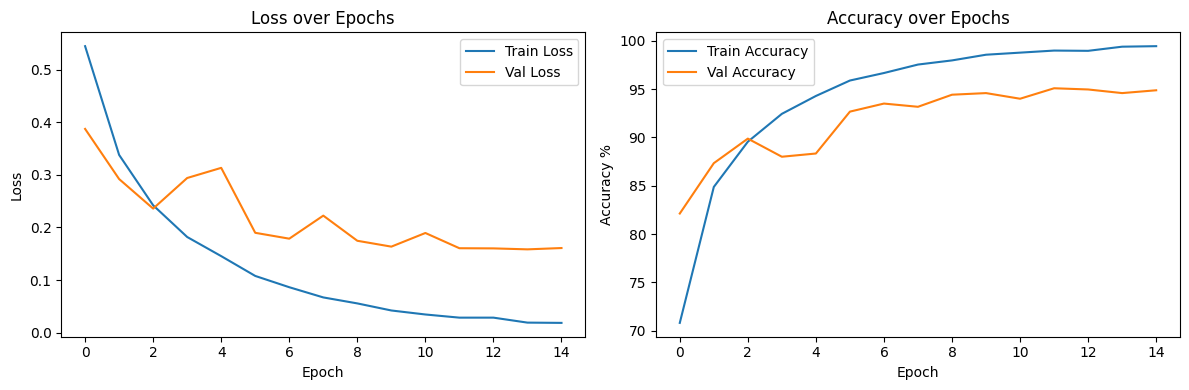

Saved to Google Drive


In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Val Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(train_accs, label='Train Accuracy')
ax2.plot(val_accs, label='Val Accuracy')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy %')
ax2.legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/training_curvesbaselinefix.png', dpi=150)
plt.show()
print("Saved to Google Drive")